# Deuxième partie — Exercice 3 : mini-BERT par mots

Un Transformer bidirectionnel entraîné **depuis zéro** pour reconstruire des mots
sélectionnés dans un corpus de phrases. Il utilise des séquences de 32 tokens,
un masquage dynamique à 15 % et la règle 80 % / 10 % / 10 %.
Le vocabulaire est construit uniquement sur les phrases d'entraînement.

In [1]:
from copy import deepcopy
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
# Deux threads suffisent pour ces petits modèles et limitent le surcoût CPU.
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RACINE = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()),
    None,
)
if RACINE is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt Architecture-Transformer.")
print("Périphérique :", device)

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
LONGUEUR = 32
EPOCHS = 100
BATCH_SIZE = 16
corpus = (RACINE / "notebooks" / "exercises" / "corpus.txt").read_text(encoding="utf-8")
phrases = [p.strip() for p in re.split(r"[.!?]+", corpus) if p.strip()]
permutation = np.random.default_rng(42).permutation(len(phrases))
frontiere = int(0.8 * len(phrases))
phrases_train = [phrases[i] for i in permutation[:frontiere]]
phrases_val = [phrases[i] for i in permutation[frontiere:]]

def tokeniser(phrase):
    return re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)*", phrase.lower(), flags=re.UNICODE)

mots = sorted({mot for phrase in phrases_train for mot in tokeniser(phrase)})
itos = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]", *mots]
stoi = {mot: i for i, mot in enumerate(itos)}
TAILLE_VOCAB = len(itos)
assert (stoi["[PAD]"], stoi["[UNK]"], stoi["[CLS]"], stoi["[SEP]"], stoi["[MASK]"]) == (0, 1, 2, 3, 4)

def encoder(phrase):
    ids = [CLS] + [stoi.get(mot, UNK) for mot in tokeniser(phrase)[:LONGUEUR - 2]] + [SEP]
    return ids + [PAD] * (LONGUEUR - len(ids))

train_ids = torch.tensor([encoder(p) for p in phrases_train], dtype=torch.long)
val_ids = torch.tensor([encoder(p) for p in phrases_val], dtype=torch.long)
train_loader = DataLoader(TensorDataset(train_ids), batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
assert train_ids.shape[1] == val_ids.shape[1] == 32
print(f"{len(phrases_train)} phrases train / {len(phrases_val)} phrases validation")
print(f"Vocabulaire train : {TAILLE_VOCAB} tokens, dont cinq tokens spéciaux")
print("Exemple :", " ".join(itos[i] for i in train_ids[0].tolist()))
val_mots = [mot for phrase in phrases_val for mot in tokeniser(phrase)[:LONGUEUR - 2]]
print(f"Mots inconnus en validation : {sum(mot not in stoi for mot in val_mots)}/{len(val_mots)}")

Périphérique : cpu
96 phrases train / 24 phrases validation
Vocabulaire train : 415 tokens, dont cinq tokens spéciaux
Exemple : [CLS] une étudiante ouvre son cahier et prépare une nouvelle expérience [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
Mots inconnus en validation : 79/222


## 1. Sélection et corruption des tokens

Chaque token ordinaire est sélectionné avec probabilité 0.15. Si aucun n'est
sélectionné dans une phrase non vide, on en choisit un au hasard. Ce minimum
augmente légèrement le taux réalisé pour les phrases courtes. Les identifiants
spéciaux, y compris `UNK`, ne sont jamais sélectionnés.

Pour chaque position sélectionnée : 80 % `[MASK]`, 10 % mot ordinaire aléatoire,
10 % token inchangé. Les cibles restent les tokens d'origine, même lorsque l'entrée
est inchangée. Toutes les autres cibles valent `-100`.

In [2]:
def masquer(input_ids, generateur):
    # Corruption sur CPU avec un générateur dédié, indépendante de la validation.
    ordinaires = input_ids >= 5
    selection = (torch.rand(input_ids.shape, generator=generateur) < 0.15) & ordinaires
    for ligne in range(len(input_ids)):
        candidats = ordinaires[ligne].nonzero(as_tuple=True)[0]
        if len(candidats) and not selection[ligne].any():
            indice = torch.randint(len(candidats), (1,), generator=generateur).item()
            selection[ligne, candidats[indice]] = True
    labels = input_ids.clone()
    labels[~selection] = -100
    corrompus = input_ids.clone()
    tirage = torch.rand(input_ids.shape, generator=generateur)
    remplacer_masque = selection & (tirage < 0.8)
    remplacer_aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)
    aleatoires = torch.randint(5, TAILLE_VOCAB, input_ids.shape, generator=generateur)
    corrompus[remplacer_masque] = MASK
    corrompus[remplacer_aleatoire] = aleatoires[remplacer_aleatoire]
    return corrompus, labels, selection

def verifier_masquage():
    # Beaucoup de tokens permettent de vérifier les proportions sans les forcer.
    exemple = torch.full((4000, 32), 5, dtype=torch.long)
    exemple[:, 0], exemple[:, -2], exemple[:, -1] = CLS, SEP, PAD
    corruption, labels, selection = masquer(exemple, torch.Generator().manual_seed(7))
    assert not selection[exemple < 5].any()
    assert selection.any(dim=1).all()
    assert torch.equal(labels != -100, selection)
    assert torch.equal(labels[selection], exemple[selection])
    assert torch.equal(corruption[~selection], exemple[~selection])
    # Au moins un mot sélectionné reste identique et possède néanmoins une cible.
    assert ((corruption == exemple) & selection & (labels != -100)).any()
    taux = selection.sum().item() / (exemple >= 5).sum().item()
    proportion_mask = (corruption[selection] == MASK).float().mean().item()
    assert 0.14 < taux < 0.17 and 0.77 < proportion_mask < 0.83
    # Une phrase sans token ordinaire ne crée aucune cible artificielle.
    vide = torch.tensor([[CLS, SEP, PAD, UNK]])
    _, labels_vides, selection_vide = masquer(vide, torch.Generator().manual_seed(1))
    assert not selection_vide.any() and (labels_vides == -100).all()
    print(f"Masquage vérifié : {taux:.1%} sélectionnés, {proportion_mask:.1%} de [MASK] parmi eux")

verifier_masquage()
val_corrompus, val_labels, val_selection = masquer(val_ids, torch.Generator().manual_seed(123))
assert val_selection.any(), "La validation doit contenir des mots connus sélectionnables."
print("Positions de validation évaluées :", val_selection.sum().item())

Masquage vérifié : 15.1% sélectionnés, 80.0% de [MASK] parmi eux
Positions de validation évaluées : 32


## 2. Encodeur bidirectionnel

Embeddings de tokens et positions de dimension 64, deux couches à quatre têtes,
puis projection vers le vocabulaire. Aucun masque causal n'est appliqué. Le masque
de padding est calculé sur les séquences **originales**, puis transmis explicitement
à l'encodeur (`True` signifie ignorer cette clé).

In [3]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, 64, padding_idx=PAD)
        self.positions = nn.Embedding(LONGUEUR, 64)
        couche = nn.TransformerEncoderLayer(
            d_model=64, nhead=4, dim_feedforward=256, dropout=0.1,
            activation="gelu", batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        for bloc in self.encodeur.layers:
            for poids in (
                bloc.self_attn.in_proj_weight, bloc.self_attn.out_proj.weight,
                bloc.linear1.weight, bloc.linear2.weight,
            ):
                nn.init.xavier_uniform_(poids)
        self.norm = nn.LayerNorm(64)
        self.sortie = nn.Linear(64, taille_vocabulaire)

    def forward(self, ids, masque_padding):
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.tokens(ids) + self.positions(positions).unsqueeze(0)
        x = self.encodeur(x, src_key_padding_mask=masque_padding)
        return self.sortie(self.norm(x))

modele = MiniBERT(TAILLE_VOCAB).to(device)
with torch.no_grad():
    assert modele(train_ids[:2].to(device), (train_ids[:2] == PAD).to(device)).shape == (2, 32, TAILLE_VOCAB)
print(f"{sum(p.numel() for p in modele.parameters()):,} paramètres")

155,679 paramètres


## 3. Vérification de l'invariance au padding

Le test remplace tous les identifiants de padding par des mots ordinaires, en
gardant le masque original. Les logits de chaque token utile doivent rester identiques.

In [4]:
def verifier_padding(modele):
    modele.eval()
    original = train_ids[:4].to(device)
    masque_padding = original == PAD
    assert masque_padding.any() and (~masque_padding).any()
    modifie = original.clone()
    modifie[masque_padding] = 5
    with torch.no_grad():
        logits_originaux = modele(original, masque_padding)
        logits_modifies = modele(modifie, masque_padding)
    torch.testing.assert_close(
        logits_originaux[~masque_padding], logits_modifies[~masque_padding],
        rtol=1e-5, atol=1e-6,
    )
    print("Padding vérifié : les logits des tokens utiles sont inchangés.")

verifier_padding(modele)

Padding vérifié : les logits des tokens utiles sont inchangés.


## 4. Entraînement avec masquage dynamique et validation fixe

On régénère la corruption à chaque batch d'entraînement. En validation, la sélection
et la corruption sont fixées pour comparer les époques. L'entropie croisée ignore
`-100` ; la perte et l'exactitude ne portent que sur les positions sélectionnées,
y compris les positions laissées inchangées. Les mots inconnus ne sont pas évalués
car leur identifiant est spécial. Le taux d'inconnus est affiché plus haut.

Avant entraînement | validation=6.2022 | exactitude=0.0%


Époque   1 | train=5.9906 | validation=5.6319 | exactitude=12.5%


Époque  10 | train=5.3121 | validation=4.7957 | exactitude=6.2%


Époque  20 | train=4.9460 | validation=4.6641 | exactitude=12.5%


Époque  30 | train=4.2605 | validation=4.9437 | exactitude=9.4%


Époque  40 | train=4.2399 | validation=4.9125 | exactitude=9.4%


... (3 outputs left out)

Époque  80 | train=3.0190 | validation=5.0988 | exactitude=15.6%


Époque  90 | train=2.7549 | validation=5.1676 | exactitude=15.6%


Époque 100 | train=2.4731 | validation=5.3092 | exactitude=12.5%


Époque retenue : 60 | perte=4.6408 | exactitude=15.6%
Padding vérifié : les logits des tokens utiles sont inchangés.


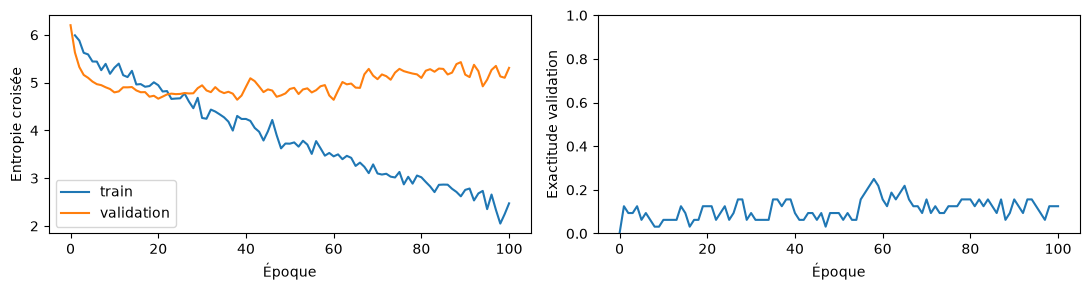

In [5]:
optimiseur = torch.optim.AdamW(modele.parameters(), lr=1e-3)
critere = nn.CrossEntropyLoss(ignore_index=-100)
generateur_masquage = torch.Generator().manual_seed(42)

def entrainer_epoque():
    modele.train()
    total, nombre = 0.0, 0
    for (originaux,) in train_loader:
        corrompus, labels, selection = masquer(originaux, generateur_masquage)
        if not selection.any():
            continue
        optimiseur.zero_grad(set_to_none=True)
        logits = modele(corrompus.to(device), (originaux == PAD).to(device))
        perte = critere(logits.reshape(-1, TAILLE_VOCAB), labels.to(device).reshape(-1))
        assert torch.isfinite(perte)
        perte.backward()
        nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()
        compte = selection.sum().item()
        total += perte.item() * compte
        nombre += compte
    return total / nombre

@torch.no_grad()
def evaluer_validation():
    modele.eval()
    logits = modele(val_corrompus.to(device), (val_ids == PAD).to(device))
    labels = val_labels.to(device)
    perte = critere(logits.reshape(-1, TAILLE_VOCAB), labels.reshape(-1)).item()
    selection = labels != -100
    exactitude = (logits.argmax(dim=-1)[selection] == labels[selection]).float().mean().item()
    return perte, exactitude

perte_initiale, exactitude_initiale = evaluer_validation()
meilleure_perte = perte_initiale
meilleurs_poids = deepcopy(modele.state_dict())
meilleure_epoque = 0
historique = [(0, float("nan"), perte_initiale, exactitude_initiale)]
print(f"Avant entraînement | validation={perte_initiale:.4f} | exactitude={exactitude_initiale:.1%}", flush=True)
for epoque in range(1, EPOCHS + 1):
    train_loss = entrainer_epoque()
    val_loss, exactitude = evaluer_validation()
    historique.append((epoque, train_loss, val_loss, exactitude))
    if val_loss < meilleure_perte:
        meilleure_perte, meilleure_epoque = val_loss, epoque
        meilleurs_poids = deepcopy(modele.state_dict())
    if epoque == 1 or epoque % 10 == 0:
        print(f"Époque {epoque:3d} | train={train_loss:.4f} | validation={val_loss:.4f} | exactitude={exactitude:.1%}", flush=True)
modele.load_state_dict(meilleurs_poids)
modele.eval()
perte_finale, exactitude_finale = evaluer_validation()
print(f"Époque retenue : {meilleure_epoque} | perte={perte_finale:.4f} | exactitude={exactitude_finale:.1%}")
verifier_padding(modele)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
epoques, pertes_train, pertes_validation, exactitudes = zip(*historique)
axes[0].plot(epoques, pertes_train, label="train")
axes[0].plot(epoques, pertes_validation, label="validation")
axes[0].set(xlabel="Époque", ylabel="Entropie croisée")
axes[0].legend()
axes[1].plot(epoques, exactitudes)
axes[1].set(xlabel="Époque", ylabel="Exactitude validation", ylim=(0, 1))
plt.tight_layout()
plt.show()

## 5. Trois propositions pour des mots masqués

On prend trois phrases de validation et on masque explicitement un mot connu
dans chacune. Les trois propositions proviennent du vocabulaire ordinaire ; on
affiche leur probabilité dans la distribution complète du modèle. Il s'agit d'une
démonstration qualitative distincte de la mesure d'exactitude ci-dessus.

In [6]:
with torch.no_grad():
    for ligne in range(min(3, len(val_ids))):
        original = val_ids[ligne:ligne + 1].to(device)
        positions = (original[0] >= 5).nonzero(as_tuple=True)[0]
        if not len(positions):
            continue
        position = positions[len(positions) // 2].item()
        cible = original[0, position].item()
        masque = original.clone()
        masque[0, position] = MASK
        logits = modele(masque, original == PAD)[0, position]
        probabilites = logits.softmax(dim=-1)
        valeurs, indices = probabilites[5:].topk(k=3)
        print("\nPhrase :", " ".join(itos[i] for i in masque[0].tolist() if i not in (PAD, CLS, SEP)))
        print("Mot attendu :", itos[cible])
        print("Top 3 :", ", ".join(f"{itos[i.item() + 5]} ({p.item():.1%})" for p, i in zip(valeurs, indices)))


Phrase : le [UNK] [UNK] des [UNK] [MASK] des [UNK] [UNK]
Mot attendu : et
Top 3 : puis (5.9%), le (4.0%), balle (3.7%)

Phrase : la température [UNK] la [UNK] [UNK] [MASK] choisir un caractère
Mot attendu : pour
Top 3 : une (2.8%), de (2.7%), présente (2.6%)

Phrase : le [UNK] reste [MASK] pendant l'entraînement
Mot attendu : caché
Top 3 : commence (13.1%), le (8.2%), la (3.4%)


## 6. Réponses aux questions

**R?sultat enregistr? :** le mod?le retenu atteint 15,6 % d?exactitude sur 32 positions de validation s?lectionn?es (5 r?ponses correctes). Les exemples affich?s montrent aussi des propositions incorrectes ; cette petite exp?rience ne constitue pas un mod?le de langue performant.

1. **Contexte à droite :** le mot à reconstruire est caché ou corrompu et l'objectif
   est une reconstruction bidirectionnelle. Il n'existe donc pas de contrainte causale :
   les mots de gauche et de droite sont disponibles pour retrouver ce mot.
2. **Perte sur les positions sélectionnées :** si toutes les positions contribuaient,
   le réseau pourrait surtout apprendre à recopier les nombreux mots visibles.
   La sélection concentre l'apprentissage sur l'objectif masqué, y compris les 10 %
   de positions sélectionnées laissées inchangées. Le padding n'est jamais une cible.
3. **Différence avec la génération GPT :** GPT apprend une factorisation de gauche
   à droite, avec une cible suivante pour chaque préfixe. Ici, le modèle apprend
   à compléter des trous dans une séquence connue des deux côtés. Il ne fournit
   pas directement la même procédure autorégressive ; une génération nécessiterait
   un autre protocole, par exemple du remplissage itératif de masques.

**Limites :** ce corpus original est très petit et la validation contient peu de mots
sélectionnés. L'exactitude varie avec la graine et la sélection ; les propositions
peuvent être incorrectes. Réutiliser la validation pour choisir les poids ne fournit
pas une estimation finale sur un test indépendant. Ce mini-modèle illustre l'objectif
de langage masqué, sans préentraînement massif ni objectif de phrase suivante.